# **2 - Análise Exploratória de Dados (EDA) e Dinâmicas de Idade**

Neste notebook, vamos explorar os dados limpos para entender os padrões históricos de mortalidade e expectativa de vida. 
Baseado na literatura demográfica recente, nossa investigação focará em:
1. **O Ritmo do Envelhecimento (Pace):** Como a Expectativa de Vida ao Nascer (`LEx`) evoluiu ao longo do tempo.
2. **Dinâmicas de Divergência e Convergência:** Identificar se diferentes grupos de países (ex: Leste Europeu vs. Europa Ocidental, ou países da América Latina) apresentam trajetórias distintas.
3. **Mortalidade Precoce vs. Tardia:** Analisar a relação da expectativa de vida com a mortalidade infantil (`Q5`) e a mortalidade adulta (`Q1560`), que são os principais motores das mudanças na igualdade da duração da vida.

In [8]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pycountry_convert as pc

In [9]:
# Configuração de estilo visual baseado no _common.py
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 10.5,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.labelsize": 10.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.alpha": 0.25, "legend.frameon": False
})

# Carregando os dados processados do Notebook 1
data_path = '../new_data/wpp2024_clean.csv'
df = pd.read_csv(data_path)
df.head()

,Pais,Codigo_ISO3,Ano,Populacao_Total,Exp_Vida_Nascer,Mort_Infantil_Sub5,Mort_Adulta_15_60,Exp_Vida_15,Exp_Vida_65,Exp_Vida_80
0,Burundi,BDI,1950,2254.938,40.9382,276.1295,423.9696,44.9163,11.0477,4.7283
1,Burundi,BDI,1951,2305.746,41.2292,273.1188,421.0379,45.0586,11.1012,4.7577
2,Burundi,BDI,1952,2355.804,41.4802,270.3369,418.7733,45.1673,11.1395,4.7776
3,Burundi,BDI,1953,2405.186,41.7429,267.4953,416.3086,45.2853,11.1807,4.7995
4,Burundi,BDI,1954,2454.586,41.9731,264.8267,414.4213,45.3754,11.2109,4.8142


In [26]:
# Separar os dados históricos (até 2023) das projeções (2024 - 2100)
df_hist = df[df['Ano'] <= 2023].copy()
df_proj = df[df['Ano'] > 2023].copy()

print(f"Total de registros históricos: {len(df_hist)}")
print(f"Total de registros projetados: {len(df_proj)}")

Total de registros históricos: 11914
Total de registros projetados: 12397


In [27]:
# 1. Função para mapear ISO3 para Continente (adaptada do Notebook 4)
def obter_continente(iso3):
    # Exceções de códigos especiais / não padronizados
    excecoes = {
        'XKX': 'Europa',   # Kosovo
        'TLS': 'Ásia',     # Timor-Leste
        'TWN': 'Ásia'      # Taiwan
    }
    if iso3 in excecoes:
        return excecoes[iso3]
    try:
        iso2 = pc.country_alpha3_to_country_alpha2(iso3)
        cod_continente = pc.country_alpha2_to_continent_code(iso2)
        continentes = {
            'AF': 'África', 
            'NA': 'América do Norte', 
            'SA': 'América do Sul', 
            'AS': 'Ásia', 
            'EU': 'Europa', 
            'OC': 'Oceania'
        }
        return continentes.get(cod_continente, 'Outros')
    except:
        return 'Outros'

In [28]:
# 2. Criando a coluna 'Continente' no DataFrame histórico
df_hist['Continente'] = df_hist['Codigo_ISO3'].apply(obter_continente)
# (Opcional) Aplica também no df completo para as projeções futuras herdarem a coluna:
df['Continente'] = df['Codigo_ISO3'].apply(obter_continente)
df_proj['Continente'] = df_proj['Codigo_ISO3'].apply(obter_continente)
# Filtramos eventuais 'Outros' para a análise continental
df_hist_cont = df_hist[df_hist['Continente'] != 'Outros'].copy()
print("Distribuição de observações por Continente:")
print(df_hist_cont['Continente'].value_counts())

Distribuição de observações por Continente:
Continente
África              3700
Ásia                3478
Europa              2664
América do Norte    1110
América do Sul       740
Oceania              222
Name: count, dtype: int64


In [29]:
# ==============================================================================
# 1. CÁLCULO DA MÉDIA PONDERADA PELA POPULAÇÃO (POR CONTINENTE E ANO)
# ==============================================================================
df_temp = df_hist_cont.copy()
# Multiplica cada indicador pela população para obter o total ponderado
indicadores = ['Exp_Vida_Nascer', 'Exp_Vida_80', 'Mort_Adulta_15_60']
for col in indicadores:
    df_temp[f'{col}_ponderado'] = df_temp[col] * df_temp['Populacao_Total']
# Agrupa por Continente e Ano, somando os ponderados e a população total
df_cont_ponderado = df_temp.groupby(['Continente', 'Ano'], as_index=False)[
    ['Populacao_Total'] + [f'{col}_ponderado' for col in indicadores]
].sum()
# Divide pelo total da população do continente para obter a média ponderada real
for col in indicadores:
    df_cont_ponderado[col] = df_cont_ponderado[f'{col}_ponderado'] / df_cont_ponderado['Populacao_Total']
print("Amostra dos dados ponderados calculados:")
print(df_cont_ponderado[['Continente', 'Ano', 'Exp_Vida_Nascer', 'Exp_Vida_80', 'Mort_Adulta_15_60']].head())

Amostra dos dados ponderados calculados:
         Continente   Ano  Exp_Vida_Nascer  Exp_Vida_80  Mort_Adulta_15_60
0  América do Norte  1950        62.808976     6.034893         249.029319
1  América do Norte  1951        63.029157     6.057666         247.669546
2  América do Norte  1952        63.341186     6.169175         243.895749
3  América do Norte  1953        63.820107     6.153355         237.293151
4  América do Norte  1954        64.615487     6.356315         226.846860


### **2.1 - Trajetórias Históricas da Expectativa de Vida e Mortalidade (1950 - 2023)**

O aumento da expectativa de vida ao longo do século XX é uma das maiores conquistas da civilização moderna. No entanto, essa evolução não foi linear para todas as nações.

Vamos selecionar um grupo de países estratégicos que a literatura aponta terem comportamentos demográficos distintos (como o avanço contínuo do Japão e da Suécia, a crise de mortalidade de adultos na Rússia no final da Guerra Fria e a trajetória da América Latina, representada pelo Brasil).

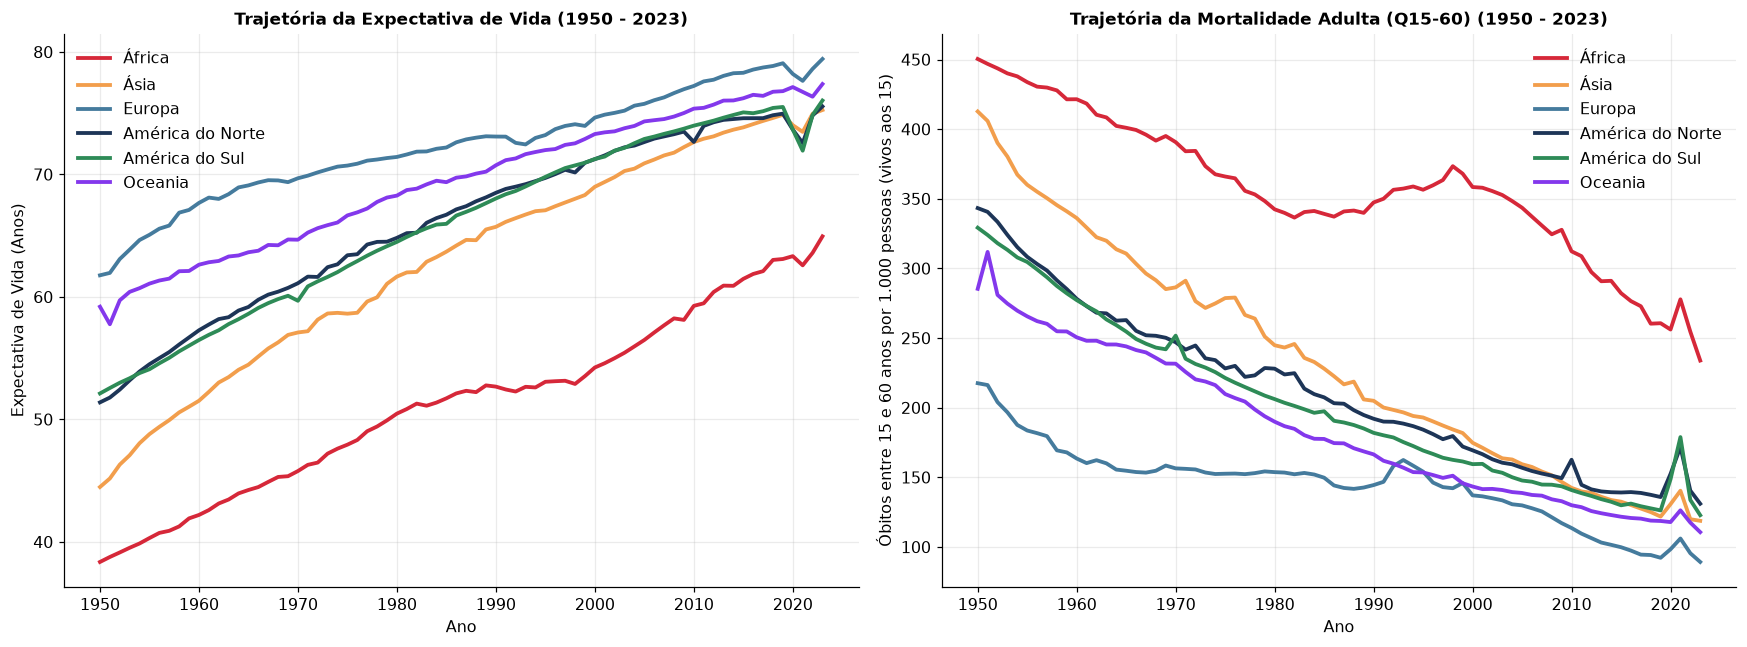

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Paleta de cores padronizada e com bom contraste para os continentes
cores_continentes = {
    'África': '#D62839',
    'Ásia': '#F29E4C',
    'América do Sul': '#2E8B57',
    'América do Norte': '#1D3557',
    'Europa': '#457B9D',
    'Oceania': '#8338EC'
}

# ==============================================================================
# PAINEL 1: EXPECTATIVA DE VIDA (Ao Nascer e aos 80 anos)
# ==============================================================================
# Linha Sólida: Ao Nascer (Exp_Vida_Nascer)
sns.lineplot(
    data=df_hist_cont, 
    x='Ano', 
    y='Exp_Vida_Nascer', 
    hue='Continente', 
    palette=cores_continentes,
    linewidth=2.5,
    errorbar=None,
    ax=axes[0]
)

axes[0].set_title('Trajetória da Expectativa de Vida (1950 - 2023)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Ano')
axes[0].set_ylabel('Expectativa de Vida (Anos)')
axes[0].legend(loc='upper left')

# ==============================================================================
# PAINEL 2: MORTALIDADE ADULTA (15 a 60 anos)
# ==============================================================================
sns.lineplot(
    data=df_hist_cont, 
    x='Ano', 
    y='Mort_Adulta_15_60', 
    hue='Continente', 
    palette=cores_continentes,
    linewidth=2.5,
    errorbar=None,
    ax=axes[1]
)

axes[1].set_title('Trajetória da Mortalidade Adulta (Q15-60) (1950 - 2023)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Ano')
axes[1].set_ylabel('Óbitos entre 15 e 60 anos por 1.000 pessoas (vivos aos 15)')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()


### **2.2 - Relação entre Expectativa de Vida e Componentes de Mortalidade**

Conforme demonstrado por [Aburto (2020)](https://doi.org/10.1073/pnas.1915884117), as melhorias na expectativa de vida, quando esta é inferior a 70 anos, são fortemente impulsionadas pela redução da **mortalidade infantil e em idades jovens** (mortes abaixo da "idade limite"). À medida que a expectativa de vida ultrapassa esse patamar, essa dinâmica muda e os ganhos passam a depender cada vez mais da redução da **mortalidade adulta e idosa** (mortes acima da "idade limite").

Para visualizar essa transição na prática, vamos plotar como a taxa de mortalidade antes dos 5 anos (`Q5`) e a probabilidade de morte entre 15 e 60 anos (`Q1560`) se comportam em relação à expectativa de vida (`LEx`) ao redor do mundo.

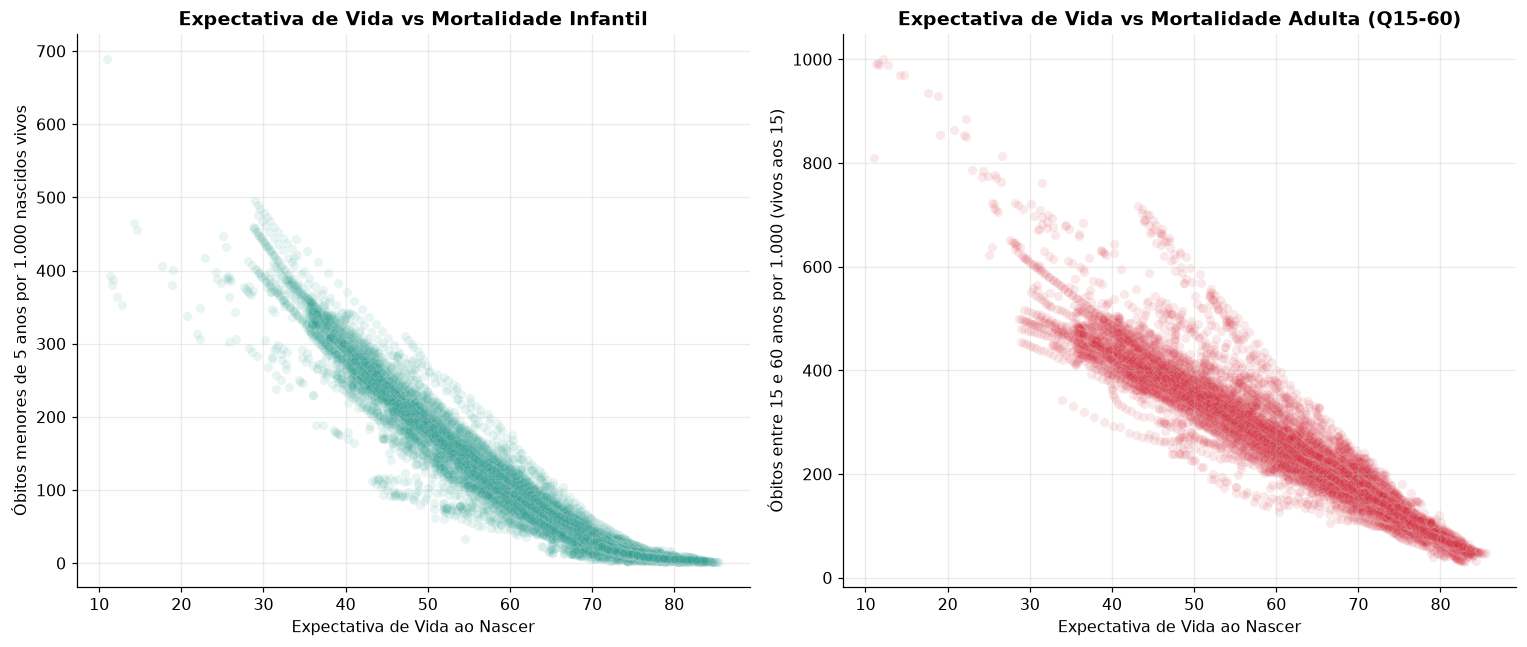

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=False)

# Gráfico 1: LEx vs Mortalidade Infantil (Q5)
sns.scatterplot(
    data=df_hist, 
    x='Exp_Vida_Nascer', 
    y='Mort_Infantil_Sub5', 
    alpha=0.1, 
    color='#2A9D8F',
    ax=axes[0]
)
axes[0].set_title('Expectativa de Vida vs Mortalidade Infantil')
axes[0].set_xlabel('Expectativa de Vida ao Nascer')
axes[0].set_ylabel('Óbitos menores de 5 anos por 1.000 nascidos vivos')

# Gráfico 2: LEx vs Mortalidade Adulta (Q1560)
sns.scatterplot(
    data=df_hist, 
    x='Exp_Vida_Nascer', 
    y='Mort_Adulta_15_60', 
    alpha=0.1, 
    color='#D62839',
    ax=axes[1]
)
axes[1].set_title('Expectativa de Vida vs Mortalidade Adulta (Q15-60)')
axes[1].set_xlabel('Expectativa de Vida ao Nascer')
axes[1].set_ylabel('Óbitos entre 15 e 60 anos por 1.000 (vivos aos 15)')

plt.tight_layout()
plt.show()

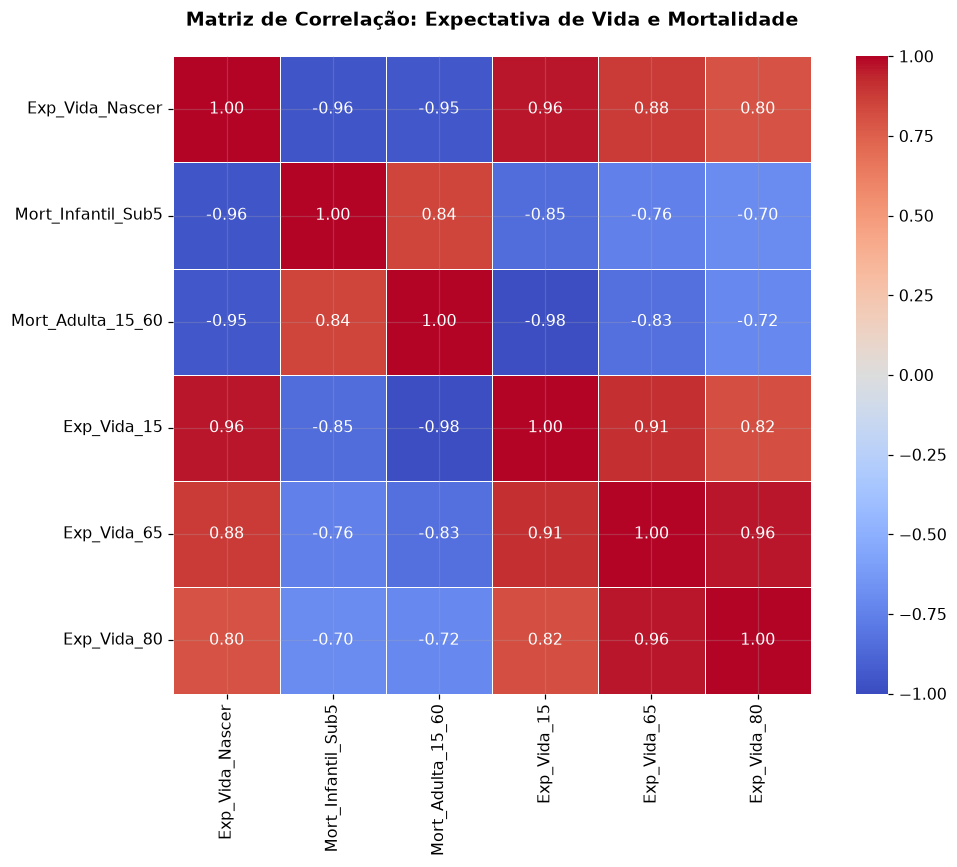

In [15]:
# Célula 7 (Markdown)
# ## 2.3 Matriz de Correlação das Variáveis de Mortalidade
# Antes de prosseguirmos para a clusterização multivariada, precisamos entender como os indicadores de diferentes faixas etárias se relacionam.

# Célula 8 (Código)
colunas_corr = [
    'Exp_Vida_Nascer', 
    'Mort_Infantil_Sub5', 
    'Mort_Adulta_15_60', 
    'Exp_Vida_15', 
    'Exp_Vida_65', 
    'Exp_Vida_80'
]

matriz_corr = df_hist[colunas_corr].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    matriz_corr, 
    annot=True, 
    cmap='coolwarm', 
    fmt=".2f", 
    vmin=-1, 
    vmax=1,
    linewidths=0.5,
    square=True
)
plt.title('Matriz de Correlação: Expectativa de Vida e Mortalidade', pad=20)
plt.tight_layout()
plt.show()

**Interpretação da Matriz de Correlação:**
* **Forte Correlação Esperada:** A Expectativa de Vida ao Nascer (`Exp_Vida_Nascer`) possui uma correlação quase perfeita e negativa com a mortalidade infantil (-0.96) e a mortalidade adulta (-0.95). 
* **A Justificativa para a Clusterização:** A correlação entre a Mortalidade Infantil (`Mort_Infantil_Sub5`) e a Expectativa de Vida aos 80 anos (`Exp_Vida_80`) é a mais fraca da matriz (-0.70). Isso evidencia demograficamente que reduzir a mortalidade na infância não garante automaticamente que a população terá uma alta sobrevida na velhice. As dinâmicas de mortalidade adulta e idosa agem de forma independente em diferentes países. 
* **Conclusão para Modelagem:** Como essas variáveis capturam dimensões diferentes e não lineares do envelhecimento, o uso de um algoritmo multivariável (como o K-Means) é a abordagem ideal para capturar o "perfil completo" (estado de mortalidade) de um país, em vez de olhar apenas para um indicador isolado.

## **2.3 - O Futuro: Explorando os Dados de Projeção (2024 - 2100)**

Até agora, analisamos as estimativas históricas (1950-2023). O arquivo "Medium" da ONU, no entanto, fornece uma série contínua que inclui a variante de projeção média até 2100. 

Vamos visualizar o que a ONU prevê para a Expectativa de Vida daqueles mesmos 5 países estratégicos. O objetivo é identificar se os modelos matemáticos da ONU preveem uma **convergência demográfica** (os países se igualando no topo) ou a manutenção das desigualdades históricas.

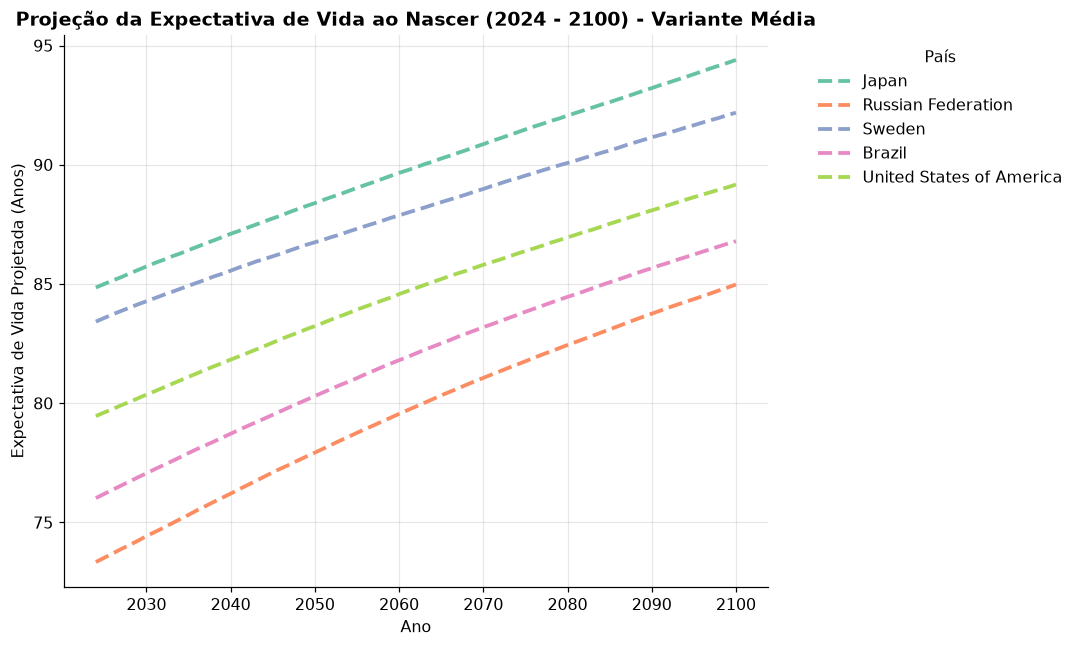

In [16]:
# Filtramos os dados de projeção para os mesmos países alvo
df_proj_alvo = df_proj[df_proj['Codigo_ISO3'].isin(paises_alvo)]

plt.figure(figsize=(10, 6))

# Plotando as projeções com estilo tracejado para diferenciar do passado
sns.lineplot(
    data=df_proj_alvo, 
    x='Ano', 
    y='Exp_Vida_Nascer', 
    hue='Pais', 
    linewidth=2.5,
    palette='Set2',
    linestyle='--'
)

plt.title('Projeção da Expectativa de Vida ao Nascer (2024 - 2100) - Variante Média')
plt.xlabel('Ano')
plt.ylabel('Expectativa de Vida Projetada (Anos)')
plt.legend(title='País', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()